
# Experiment No. 10: Single-Layer Artificial Neural Network

## Aim
To build and implement a single-layer Artificial Neural Network (ANN) using Python to solve a simple classification problem.

## Objectives
1. To understand the basic structure and working of a single-layer Artificial Neural Network.
2. To implement a neural network using Python and the NumPy library.
3. To train the network using input data and predict the class of new data.
4. To evaluate the performance of the network on a simple classification problem.

## Relevance
Artificial Neural Networks are Machine Learning models inspired by the human brain. They learn patterns from training examples and make predictions.

A single-layer ANN is useful for understanding the fundamentals of neural networks and binary classification. It provides a foundation for advanced neural networks and deep learning.

## Theory

### 1. Artificial Neural Network (ANN)
An ANN consists of interconnected processing units called neurons. It learns from training data by adjusting weights and biases.

### 2. Single-Layer ANN
A single-layer ANN has an input layer directly connected to an output layer, without a hidden layer. In this experiment, one sigmoid neuron performs binary classification.

### 3. Components
- **Input:** Features provided to the network.
- **Weights:** Values representing the importance of each input.
- **Bias:** An additional trainable value.
- **Weighted sum:** The sum of weighted inputs and bias.
- **Activation function:** Converts the weighted sum into an output.
- **Output:** The predicted class.

### 4. Mathematical Model

Weighted sum:

z = w₁x₁ + w₂x₂ + ... + wₙxₙ + b

Sigmoid activation function:

σ(z) = 1 / (1 + e⁻ᶻ)

The sigmoid function produces an output between 0 and 1. Using a threshold of 0.5:

- If σ(z) ≥ 0.5, predict class 1.
- If σ(z) < 0.5, predict class 0.

### 5. Learning Process
The network calculates predictions, compares them with actual labels, and updates its weights and bias using gradient descent.

Binary cross-entropy loss:

L = −[y log(p) + (1 − y) log(1 − p)]

Here, y is the actual label and p is the predicted probability. Training repeats over multiple epochs to minimize the loss.

### 6. Dataset
The Breast Cancer Wisconsin dataset available in scikit-learn is used for binary classification. Two features—mean radius and mean texture—are selected for visualization and model training.

### 7. Evaluation
The model is evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

## Libraries Required
- NumPy
- Pandas
- Matplotlib
- Scikit-learn

## Reference
https://github.com/rasbt/pattern_classification/blob/master/machine_learning/singlelayer_neural_networks/singlelayer_neural_networks.ipynb



## Step 1: Import Libraries

Import the required Python libraries. NumPy performs numerical calculations, Pandas manages tabular data, Matplotlib creates graphs, and scikit-learn provides the dataset, preprocessing tools, and evaluation metrics.

The environment variable below helps avoid a known Windows MKL warning if scikit-learn's K-Means functionality is used in other experiments. It is not required for the ANN itself.


In [1]:

import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")


Libraries imported successfully.



## Step 2: Load the Dataset

Load the Breast Cancer Wisconsin dataset. The original dataset contains measurements of cell nuclei and two classes: malignant and benign.

For this experiment, class 0 represents malignant and class 1 represents benign.


In [2]:

dataset = load_breast_cancer()

df = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

df["target"] = dataset.target

print("Dataset loaded successfully.")
print("Class labels:", dataset.target_names)


Dataset loaded successfully.
Class labels: ['malignant' 'benign']



## Step 3: Display the Dataset

Display the first five records to understand how the dataset is organized and how its numerical features are represented.


In [3]:

df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



## Step 4: Examine Dataset Information

Check the number of records, available columns, and data types. This helps us understand the structure of the dataset before selecting input features.


In [4]:

print("Dataset shape:", df.shape)
print("\nAvailable features:")
print(dataset.feature_names)
print("\nDataset information:")
df.info()


Dataset shape: (569, 31)

Available features:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean are


## Step 5: Check Data Quality

Check whether the dataset contains missing values or duplicate records. Data-quality checks help prevent avoidable issues during model training.


In [5]:

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Missing values: 0
Duplicate rows: 0



## Step 6: Examine Class Distribution

Count the observations in each class. This helps us understand whether both classes are represented adequately in the dataset.


,Class,Diagnosis,Count
0,0,malignant,212
1,1,benign,357


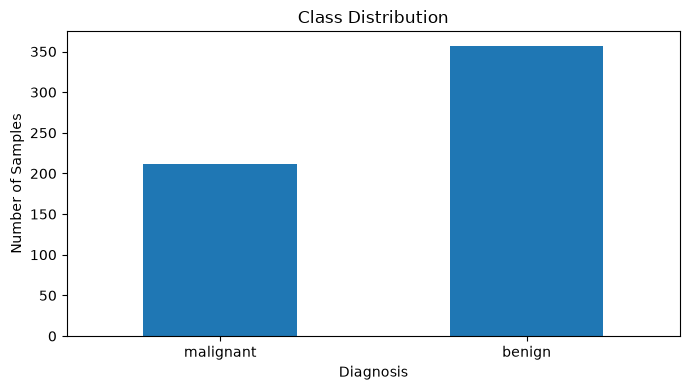

In [6]:

class_counts = df["target"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": [0, 1],
    "Diagnosis": dataset.target_names,
    "Count": class_counts.values
})

display(class_distribution)

class_distribution.plot(
    x="Diagnosis",
    y="Count",
    kind="bar",
    legend=False,
    figsize=(7, 4)
)

plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



## Step 7: Select Features and Target

Select mean radius and mean texture as the two input features. The target is the diagnosis label.

Only two features are used to make the model easier to visualize. The target label is not included among the input features.


In [7]:

feature_names = ["mean radius", "mean texture"]

X = df[feature_names].to_numpy(dtype=float)
y = df["target"].to_numpy(dtype=int)

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Selected features:", feature_names)


Input shape: (569, 2)
Target shape: (569,)
Selected features: ['mean radius', 'mean texture']



## Step 8: Visualize the Original Data

Plot the two selected features and use different markers or colors for the two diagnosis classes. The graph helps us inspect how the classes are distributed before training.


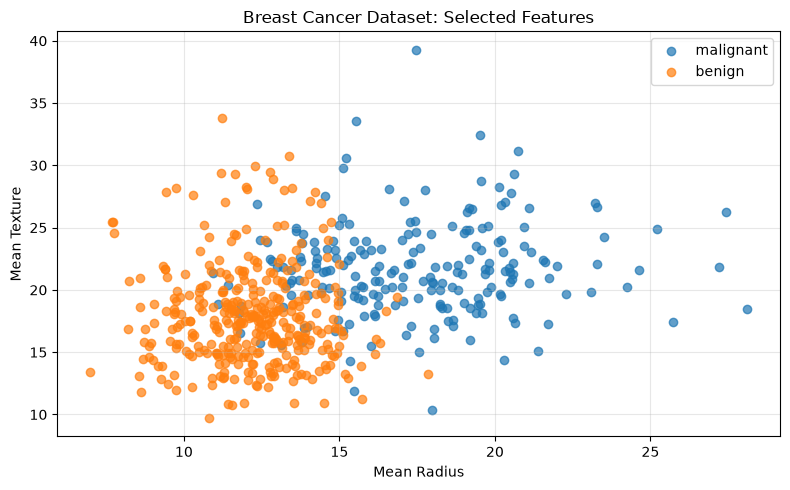

In [8]:

plt.figure(figsize=(8, 5))

for class_id, label in enumerate(dataset.target_names):
    mask = y == class_id
    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        label=label,
        alpha=0.7
    )

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Breast Cancer Dataset: Selected Features")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## Step 9: Split into Training and Testing Sets

Divide the data into 80% training and 20% testing sets. The ANN learns from the training set, while the testing set evaluates its performance on unseen examples.

Stratification preserves approximately the same class proportions in both sets.


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 455
Testing samples: 114



## Step 10: Feature Scaling

Standardize the features so that they have approximately zero mean and unit variance. Scaling helps gradient descent train more effectively when input features have different numerical ranges.

Fit the scaler only on the training data to avoid information leakage from the test set.


In [10]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First five standardized training samples:")
print(X_train_scaled[:5])


First five standardized training samples:
[[-1.07200079 -0.6584246 ]
 [ 1.74874285  0.06650173]
 [-0.97473376 -0.93112416]
 [-0.14510328 -1.2151862 ]
 [-0.77161734 -0.08121053]]



## Step 11: Define the Activation Function

The sigmoid function converts the weighted sum into a probability between 0 and 1. Initialize the weights and bias for one output neuron.

Because two features are used, the network has two weights and one bias.


In [11]:

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

n_features = X_train_scaled.shape[1]

weights = np.zeros(n_features)
bias = 0.0

print("Initial weights:", weights)
print("Initial bias:", bias)


Initial weights: [0. 0.]
Initial bias: 0.0



## Step 12: Define the Loss Function

Binary cross-entropy measures the difference between the actual binary labels and the probabilities predicted by the network.

A smaller loss indicates that the predicted probabilities are closer to the actual labels. Clipping the probabilities prevents taking the logarithm of zero.


In [12]:

def binary_cross_entropy(y_true, probabilities):
    epsilon = 1e-12
    probabilities = np.clip(
        probabilities,
        epsilon,
        1 - epsilon
    )

    loss = -np.mean(
        y_true * np.log(probabilities)
        + (1 - y_true) * np.log(1 - probabilities)
    )

    return loss

initial_probabilities = sigmoid(
    X_train_scaled @ weights + bias
)

print(
    "Initial training loss:",
    binary_cross_entropy(y_train, initial_probabilities)
)


Initial training loss: 0.6931471805599453



## Step 13: Train the Neural Network

Train the single sigmoid neuron using gradient descent.

For each epoch:
1. Calculate the weighted sum.
2. Apply the sigmoid function.
3. Calculate the prediction error.
4. Calculate gradients for the weights and bias.
5. Update the parameters to reduce the loss.

The model is trained using only the training data.


In [13]:

learning_rate = 0.1
epochs = 3000
loss_history = []

n_samples = X_train_scaled.shape[0]

for epoch in range(epochs):
    z = X_train_scaled @ weights + bias
    probabilities = sigmoid(z)

    loss = binary_cross_entropy(y_train, probabilities)
    loss_history.append(loss)

    error = probabilities - y_train

    dw = (X_train_scaled.T @ error) / n_samples
    db = np.mean(error)

    weights -= learning_rate * dw
    bias -= learning_rate * db

print("Training completed.")
print("Final weights:", weights)
print("Final bias:", bias)
print("Final training loss:", loss_history[-1])


Training completed.
Final weights: [-3.73596694 -0.89464266]
Final bias: 0.6795923484589497
Final training loss: 0.25582194216823745



## Step 14: Visualize Training Progress

Plot binary cross-entropy loss against the number of epochs. A decreasing curve indicates that the network is learning from the training data.


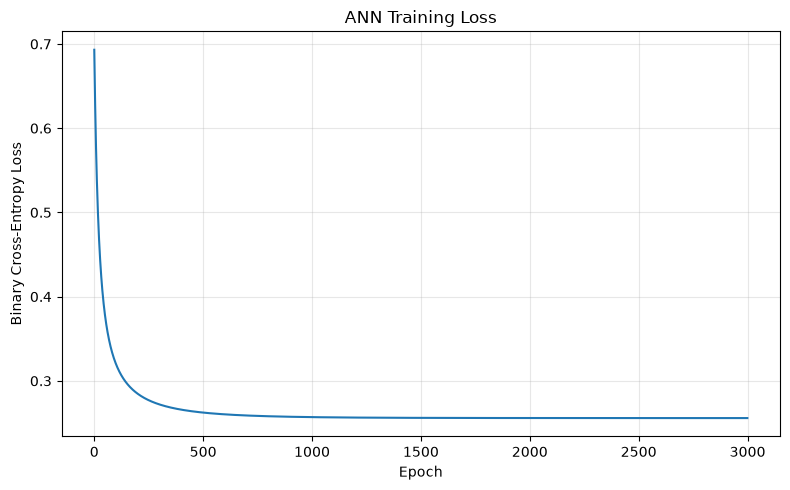

In [14]:

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("ANN Training Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## Step 15: Predict Test Probabilities

Use the trained weights and bias to calculate sigmoid probabilities for the testing set. These probabilities represent the model's estimated probability of class 1 (benign).


In [15]:

test_probabilities = sigmoid(
    X_test_scaled @ weights + bias
)

results = pd.DataFrame({
    "Actual Class": y_test,
    "Predicted Probability of Class 1": test_probabilities
})

results.head(10)


,Actual Class,Predicted Probability of Class 1
0,0,0.000811
1,1,0.987295
2,0,0.469524
3,1,0.151114
4,0,0.000346
5,1,0.863820
6,1,0.999079
7,0,0.002977
8,0,0.015891
9,0,0.000236



## Step 16: Classify Using a Threshold

Apply a threshold of 0.5 to convert predicted probabilities into class labels.

- Probability greater than or equal to 0.5: predict class 1 (benign).
- Probability below 0.5: predict class 0 (malignant).


In [16]:

y_pred = (test_probabilities >= 0.5).astype(int)

prediction_results = pd.DataFrame({
    "Actual Class": y_test,
    "Predicted Class": y_pred,
    "Predicted Probability": np.round(test_probabilities, 4)
})

prediction_results.head(15)


,Actual Class,Predicted Class,Predicted Probability
0,0,0,0.0008
1,1,1,0.9873
2,0,0,0.4695
3,1,0,0.1511
4,0,0,0.0003
5,1,1,0.8638
6,1,1,0.9991
7,0,0,0.0030
8,0,0,0.0159
9,0,0,0.0002



## Step 17: Calculate Evaluation Metrics

Calculate accuracy, precision, recall, and F1-score using the test predictions.

- **Accuracy:** Proportion of all predictions that are correct.
- **Precision:** Proportion of predicted positive cases that are actually positive.
- **Recall:** Proportion of actual positive cases correctly identified.
- **F1-score:** Harmonic mean of precision and recall.

For this experiment, class 1 (benign) is treated as the positive class.


In [17]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [accuracy, precision, recall, f1]
})

display(metrics)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=dataset.target_names,
        zero_division=0
    )
)


,Metric,Score
0,Accuracy,0.877193
1,Precision,0.902778
2,Recall,0.902778
3,F1-score,0.902778



Classification Report:
              precision    recall  f1-score   support

   malignant       0.83      0.83      0.83        42
      benign       0.90      0.90      0.90        72

    accuracy                           0.88       114
   macro avg       0.87      0.87      0.87       114
weighted avg       0.88      0.88      0.88       114




## Step 18: Plot the Confusion Matrix

A confusion matrix compares actual class labels with predicted class labels. It shows correct and incorrect predictions for each class.


Confusion Matrix:
[[35  7]
 [ 7 65]]


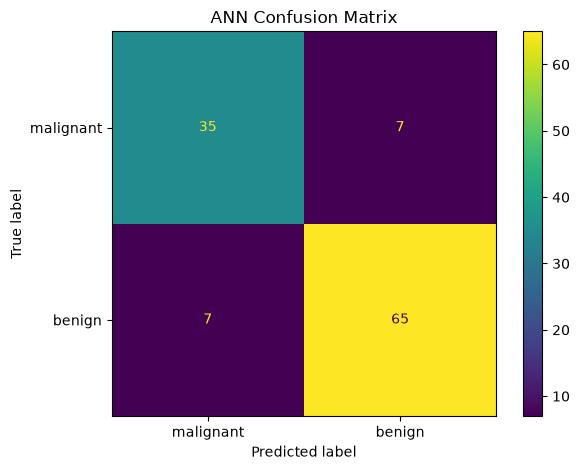

In [18]:

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display_labels = [
    dataset.target_names[0],
    dataset.target_names[1]
]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(values_format="d")
plt.title("ANN Confusion Matrix")
plt.tight_layout()
plt.show()



## Step 19: Visualize the Decision Boundary

Create a grid across the two standardized features and calculate predictions for every grid point. Plot the resulting decision regions together with the training observations.

This visualization illustrates how the single-layer ANN separates the two classes. The decision boundary of one sigmoid neuron is linear in the input features.


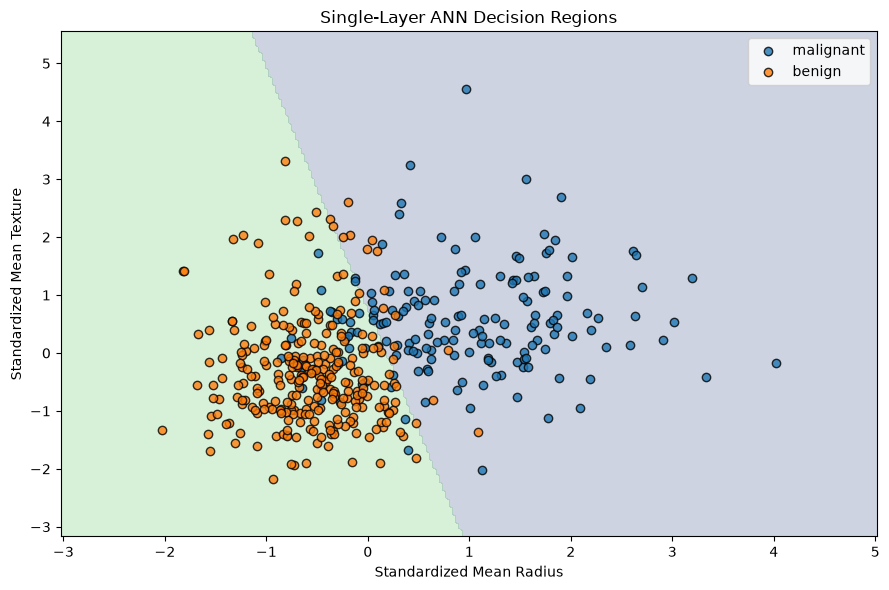

In [19]:

x_min = X_train_scaled[:, 0].min() - 1
x_max = X_train_scaled[:, 0].max() + 1
y_min = X_train_scaled[:, 1].min() - 1
y_max = X_train_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_probabilities = sigmoid(grid @ weights + bias)
grid_predictions = (grid_probabilities >= 0.5).astype(int)
regions = grid_predictions.reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contourf(
    xx,
    yy,
    regions,
    alpha=0.25,
    levels=[-0.5, 0.5, 1.5]
)

for class_id, label in enumerate(dataset.target_names):
    mask = y_train == class_id
    plt.scatter(
        X_train_scaled[mask, 0],
        X_train_scaled[mask, 1],
        label=label,
        edgecolors="black",
        alpha=0.8
    )

plt.xlabel("Standardized Mean Radius")
plt.ylabel("Standardized Mean Texture")
plt.title("Single-Layer ANN Decision Regions")
plt.legend()
plt.tight_layout()
plt.show()



## Step 20: Predict a New Sample

Provide a new sample using mean radius and mean texture. Standardize it using the scaler fitted on the training data, then use the trained ANN to predict its class.

The example values below are illustrative. This prediction is only for demonstrating the model and must not be used for medical diagnosis.


In [20]:

new_sample = pd.DataFrame(
    [[15.0, 20.0]],
    columns=feature_names
)

new_sample_scaled = scaler.transform(new_sample)

new_probability = sigmoid(
    new_sample_scaled @ weights + bias
)[0]

new_prediction = int(new_probability >= 0.5)

print("New sample:")
display(new_sample)

print(f"Probability of benign class: {new_probability:.4f}")
print("Predicted class:", dataset.target_names[new_prediction])
print("Predicted class number:", new_prediction)
print("\nLearned weights:", weights)
print("Learned bias:", bias)


New sample:


C:\B-TECH\AnacondaFiles\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


,mean radius,mean texture
0,15.0,20.0


Probability of benign class: 0.3845
Predicted class: malignant
Predicted class number: 0

Learned weights: [-3.73596694 -0.89464266]
Learned bias: 0.6795923484589497



# Conclusion

Thus, a single-layer Artificial Neural Network was implemented successfully using Python and NumPy for a binary classification problem.

The network used a sigmoid activation function to calculate prediction probabilities and gradient descent to update its weights and bias. The trained model predicted class labels using a threshold of 0.5.

The model's performance was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. The training loss and decision boundary were also visualized to understand the learning process.

This experiment demonstrates the fundamental working of a single-layer ANN and provides a foundation for studying more advanced neural networks.
